# Лабораторная работа №3. Решающее дерево

## Цель работы

В этой работе я сравниваю решающие деревья из sklearn и реализации
на NumPy для двух задач: покупки страховки и цены ноутбука.
Для каждой задачи проверяю исходные настройки и вариант после подбора.

## Данные и метрики

Используются те же наборы и разбиения, что в ЛР1 и ЛР2:

- [Travel Insurance Prediction Data](https://www.kaggle.com/datasets/tejashvi14/travel-insurance-prediction-data): цель TravelInsurance. Основная метрика — macro-F1, дополнительно Accuracy, ROC-AUC и матрица ошибок. Macro-F1 учитывает качество обоих классов при разном числе покупателей и непокупателей.
- [Laptop Prices](https://www.kaggle.com/datasets/owm4096/laptop-prices): цель Price_euros. Основная метрика — MAE в евро, дополнительно RMSE и R². MAE показывает среднюю абсолютную ошибку цены; RMSE сильнее реагирует на крупные промахи.

Прогноз покупки может помочь выбрать клиентов для предложения полиса.
Прогноз цены позволяет сопоставлять ноутбуки по характеристикам.
Цены относятся к исходному набору данных.

## Проверка окружения

Сначала вывожу версии библиотек и задаю random_state=42.

In [1]:
# Проверяем окружение для решающих деревьев.
import sys
import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    StratifiedGroupKFold, GroupShuffleSplit, GroupKFold, cross_validate,
)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.13.18
NumPy: 2.4.6
pandas: 2.2.3
scikit-learn: 1.6.1


## Загрузка данных

Используются исходные CSV из ЛР1. Перед чтением проверяются их контрольные
суммы: файлы и порядок строк должны совпадать с первым исследованием.

In [2]:
# Загружаем два исходных CSV.
from google.colab import files

uploaded = files.upload()

Saving laptop_prices.csv to laptop_prices.csv
Saving TravelInsurancePrediction.csv to TravelInsurancePrediction.csv


In [3]:
# Проверяем версии исходных файлов и читаем таблицы.
source_hashes = {
    "TravelInsurancePrediction.csv": "26c79f34d14138771983be3dc2dbf019c6e8b20d78db9109261149dec63da426",
    "laptop_prices.csv": "3638d6dc2c50b89263c99b364173a1f773e0b1fb0b83aa080749e95b7a77da8d"
}

for filename, expected_hash in source_hashes.items():
    actual_hash = hashlib.sha256(Path(filename).read_bytes()).hexdigest()
    assert actual_hash == expected_hash, (
        f"Файл {filename} отличается от использованного в ЛР1."
    )

travel = pd.read_csv("TravelInsurancePrediction.csv")
laptops = pd.read_csv("laptop_prices.csv")

# Проверяем и исключаем служебный индекс.
assert np.array_equal(travel["Unnamed: 0"].to_numpy(), np.arange(len(travel)))
travel = travel.drop(columns="Unnamed: 0")

print("Страховка:", travel.shape)
print("Ноутбуки:", laptops.shape)
print("Пропуски:", travel.isna().sum().sum(), laptops.isna().sum().sum())

Страховка: (1987, 9)
Ноутбуки: (1275, 23)
Пропуски: 0 0


## Разбиения из ЛР1

Строки с одинаковыми входными признаками объединены в группы. Одна группа
целиком попадает в train или test; это позволяет проверить прогнозы на
новых сочетаниях характеристик. Целевая переменная в группы не входит.

Для страховки используется первая часть StratifiedGroupKFold из пяти,
для ноутбуков — GroupShuffleSplit с 20% групп в тесте. Настройки и seed
сохранены из ЛР1. Результат разделения и три части CV проверяются по
контрольным суммам распределения строк. Ноутбук запускается отдельно от ЛР1.

Набор входных столбцов также сохранён. Для ноутбуков исключены Product,
CPU_model и GPU_model, чтобы ограничить число редких категорий.

In [4]:
# Восстанавливаем признаки и разбиения по протоколу ЛР1.
classification_features = [
    "Age",
    "Employment Type",
    "GraduateOrNot",
    "AnnualIncome",
    "FamilyMembers",
    "ChronicDiseases",
    "FrequentFlyer",
    "EverTravelledAbroad"
]
regression_features = [
    "Company",
    "TypeName",
    "Inches",
    "Ram",
    "OS",
    "Weight",
    "Screen",
    "ScreenW",
    "ScreenH",
    "Touchscreen",
    "IPSpanel",
    "RetinaDisplay",
    "CPU_company",
    "CPU_freq",
    "PrimaryStorage",
    "SecondaryStorage",
    "PrimaryStorageType",
    "SecondaryStorageType",
    "GPU_company"
]
expected_protocol = {
    "travel": {
        "test_mask_sha256": "26baec97124eb0502e188b8451b25f110001b8c5d7c7ef7e0391b2982f09e97d",
        "cv_assignment_sha256": "96aebde84f18d8298cb2013035e3499b7c42e5103e5b95d8b337f7afb125d321"
    },
    "laptops": {
        "test_mask_sha256": "88fed4bc26da4cdd5bf8d6edb965a0e27322070907a2b50ab0017abc9cb97b3d",
        "cv_assignment_sha256": "68661b03ff5b016ab29e97c79596e6f67bedd74821bd782b3b9943f27edb7f45"
    }
}

X_cls = travel[classification_features].copy()
y_cls = travel["TravelInsurance"].copy()
X_reg = laptops[regression_features].copy()
y_reg = laptops["Price_euros"].copy()

groups_cls = pd.factorize(pd.MultiIndex.from_frame(X_cls))[0]
groups_reg = pd.factorize(pd.MultiIndex.from_frame(X_reg))[0]

split_cls = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE,
)
train_idx_cls, test_idx_cls = next(split_cls.split(X_cls, y_cls, groups_cls))
split_reg = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=RANDOM_STATE,
)
train_idx_reg, test_idx_reg = next(split_reg.split(X_reg, y_reg, groups_reg))

X_train_cls, X_test_cls = X_cls.iloc[train_idx_cls].copy(), X_cls.iloc[test_idx_cls].copy()
y_train_cls, y_test_cls = y_cls.iloc[train_idx_cls].copy(), y_cls.iloc[test_idx_cls].copy()
X_train_reg, X_test_reg = X_reg.iloc[train_idx_reg].copy(), X_reg.iloc[test_idx_reg].copy()
y_train_reg, y_test_reg = y_reg.iloc[train_idx_reg].copy(), y_reg.iloc[test_idx_reg].copy()
groups_train_cls = groups_cls[train_idx_cls]
groups_train_reg = groups_reg[train_idx_reg]

cv_cls = StratifiedGroupKFold(
    n_splits=3, shuffle=True, random_state=RANDOM_STATE,
)
cv_reg = GroupKFold(n_splits=3)
cv_folds_cls = list(cv_cls.split(X_train_cls, y_train_cls, groups_train_cls))
cv_folds_reg = list(cv_reg.split(X_train_reg, y_train_reg, groups_train_reg))

def text_hash(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

# Проверяем номера строк test и распределение train по частям CV.
for name, X, groups, train_idx, test_idx, folds in [
    ("travel", X_cls, groups_cls, train_idx_cls, test_idx_cls, cv_folds_cls),
    ("laptops", X_reg, groups_reg, train_idx_reg, test_idx_reg, cv_folds_reg),
]:
    mask = np.zeros(len(X), dtype=int)
    mask[test_idx] = 1
    assert text_hash("".join(map(str, mask))) == expected_protocol[name]["test_mask_sha256"]
    assert not (set(groups[train_idx]) & set(groups[test_idx]))

    codes = np.full(len(X), "-", dtype="<U1")
    for fold_number, (fit_positions, valid_positions) in enumerate(folds):
        assert not (
            set(groups[train_idx[fit_positions]])
            & set(groups[train_idx[valid_positions]])
        )
        codes[train_idx[valid_positions]] = str(fold_number)
    assert text_hash("".join(codes)) == expected_protocol[name]["cv_assignment_sha256"]
    print(f"{name}: train={len(train_idx)}, test={len(test_idx)}; разбиения совпали с ЛР1")

travel: train=1543, test=444; разбиения совпали с ЛР1
laptops: train=1009, test=266; разбиения совпали с ЛР1


## Исходные библиотечные модели

Для классификации используется DecisionTreeClassifier с критерием Gini,
для регрессии — DecisionTreeRegressor с критерием squared_error.
В исходном варианте глубина не ограничена, минимальный размер листа — один объект.
Для сравнения также оцениваются Dummy-модели.

Числовые признаки передаются без масштабирования: дерево выбирает пороги
отдельных признаков. Категории кодируются OneHotEncoder внутри Pipeline;
кодировщик обучается только на обучающей части каждого разбиения CV.
Неизвестная категория кодируется нулями в соответствующем блоке.

Используются три зафиксированные групповые части CV. Тестовая выборка
на этом этапе не участвует в оценке или выборе настроек.

In [5]:
# Оцениваем исходные деревья и Dummy на фиксированных частях CV.
def make_tree_preprocessor(X):
    numeric_columns = X.select_dtypes(include="number").columns.tolist()
    categorical_columns = [c for c in X.columns if c not in numeric_columns]
    return ColumnTransformer([
        ("numeric", "passthrough", numeric_columns),
        ("categorical", OneHotEncoder(
            handle_unknown="ignore", sparse_output=False,
        ), categorical_columns),
    ])


def make_tree_pipeline(X, model):
    return Pipeline([
        ("preprocessor", make_tree_preprocessor(X)),
        ("model", model),
    ])


def evaluate_tree_models(models, X, y, folds, scoring):
    rows = []
    for name, model in models.items():
        scores = cross_validate(
            make_tree_pipeline(X, model), X, y, cv=folds,
            scoring=scoring, n_jobs=-1, error_score="raise",
        )
        row = {"model": name}
        for metric, scorer in scoring.items():
            values = scores[f"test_{metric}"]
            if scorer.startswith("neg_"):
                values = -values
            row[f"{metric}_mean"] = values.mean()
            row[f"{metric}_std"] = values.std(ddof=1)
        rows.append(row)
    return pd.DataFrame(rows)


scoring_cls = {"macro_f1": "f1_macro", "accuracy": "accuracy", "roc_auc": "roc_auc"}
scoring_reg = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
}

baseline_cv_cls = evaluate_tree_models(
    {
        "Dummy": DummyClassifier(strategy="most_frequent"),
        "DecisionTree baseline": DecisionTreeClassifier(random_state=RANDOM_STATE),
    },
    X_train_cls, y_train_cls, cv_folds_cls, scoring_cls,
)
baseline_cv_reg = evaluate_tree_models(
    {
        "Dummy": DummyRegressor(strategy="median"),
        "DecisionTree baseline": DecisionTreeRegressor(random_state=RANDOM_STATE),
    },
    X_train_reg, y_train_reg, cv_folds_reg, scoring_reg,
)

results_dir = Path("/content/results")
results_dir.mkdir(parents=True, exist_ok=True)
baseline_cv_cls.to_csv(results_dir / "lab3_baseline_cv_classification.csv", index=False)
baseline_cv_reg.to_csv(results_dir / "lab3_baseline_cv_regression.csv", index=False)

print("Классификация: исходные модели на CV")
display(baseline_cv_cls.round(4))
print("Регрессия: исходные модели на CV")
display(baseline_cv_reg.round(4))

Классификация: исходные модели на CV


,model,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std
0,Dummy,0.3893,0.0087,0.6378,0.0235,0.5000,0.0000
1,DecisionTree baseline,0.7351,0.0341,0.7635,0.0288,0.7458,0.0505


Регрессия: исходные модели на CV


,model,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
0,Dummy,528.9241,8.4828,722.8491,14.0135,-0.0517,0.0085
1,DecisionTree baseline,259.8890,12.5414,391.1706,27.6117,0.6915,0.0360


## Ограничение сложности дерева

Исходное дерево получило на CV macro-F1 = 0.7351 для страховки
и MAE = 259.89 евро для цены ноутбука. Обе модели лучше Dummy.

Проверяется гипотеза, что ограничение глубины и увеличение минимального
размера листа уменьшат переобучение. Для классификации также проверяются
веса классов: balanced увеличивает вклад менее представленного класса.

В сетку включён исходный вариант: глубина без ограничения, один объект
в листе и без весов классов. Параметры выбираются по macro-F1 и MAE
на тех же частях CV. Тестовая выборка не используется.
Дополнительно сравниваются метрики на обучающих и проверочных частях CV.
Для выбора настроек использую CV, а итоговое качество проверяю на тесте.

In [6]:
"""Проверяем ограничения сложности дерева на фиксированной групповой CV."""

from sklearn.model_selection import GridSearchCV


# Глубина ограничивает число последовательных условий, размер листа —
# минимальное число обучающих наблюдений, по которым делается прогноз.
search_cls = GridSearchCV(
    estimator=make_tree_pipeline(
        X_train_cls, DecisionTreeClassifier(random_state=RANDOM_STATE),
    ),
    param_grid={
        "model__max_depth": [3, 5, 8, None],
        "model__min_samples_leaf": [1, 3, 10, 25],
        "model__class_weight": [None, "balanced"],
    },
    scoring=scoring_cls,
    refit="macro_f1",
    cv=cv_folds_cls,
    return_train_score=True,
    n_jobs=-1,
    error_score="raise",
    verbose=1,
)
search_reg = GridSearchCV(
    estimator=make_tree_pipeline(
        X_train_reg, DecisionTreeRegressor(random_state=RANDOM_STATE),
    ),
    param_grid={
        "model__max_depth": [3, 5, 8, None],
        "model__min_samples_leaf": [1, 3, 10, 25],
    },
    scoring=scoring_reg,
    refit="mae",
    cv=cv_folds_reg,
    return_train_score=True,
    n_jobs=-1,
    error_score="raise",
    verbose=1,
)

search_cls.fit(X_train_cls, y_train_cls)
search_reg.fit(X_train_reg, y_train_reg)


def selected_cv_row(search, scoring, name, n_folds):
    # Считаем разброс с ddof=1, как в таблице исходных моделей.
    i = search.best_index_
    row = {"model": name}
    for metric, scorer in scoring.items():
        values = np.array([
            search.cv_results_[f"split{fold}_test_{metric}"][i]
            for fold in range(n_folds)
        ])
        if scorer.startswith("neg_"):
            values = -values
        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std(ddof=1)
    return row


tree_search_cv_cls = pd.concat([
    baseline_cv_cls,
    pd.DataFrame([selected_cv_row(
        search_cls, scoring_cls, "DecisionTree tuned", len(cv_folds_cls),
    )]),
], ignore_index=True)
tree_search_cv_reg = pd.concat([
    baseline_cv_reg,
    pd.DataFrame([selected_cv_row(
        search_reg, scoring_reg, "DecisionTree tuned", len(cv_folds_reg),
    )]),
], ignore_index=True)

print("Классификация: выбранные параметры", search_cls.best_params_)
display(tree_search_cv_cls.round(4))
print("Регрессия: выбранные параметры", search_reg.best_params_)
display(tree_search_cv_reg.round(4))

# Сравниваем качество на обучающих и проверочных частях каждого CV-фолда.
# Полный train здесь не используется как проверочная выборка.
complexity_rows = []
for task, search, metric, sign in [
    ("classification", search_cls, "macro_f1", 1),
    ("regression", search_reg, "mae", -1),
]:
    for variant, parameters in [("baseline", None), ("tuned", search.best_params_)]:
        if parameters is None:
            candidates = [
                i for i, p in enumerate(search.cv_results_["params"])
                if p["model__max_depth"] is None
                and p["model__min_samples_leaf"] == 1
                and p.get("model__class_weight") is None
            ]
            assert len(candidates) == 1
            i = candidates[0]
        else:
            i = search.best_index_
        complexity_rows.append({
            "task": task,
            "variant": variant,
            "metric": metric,
            "train_mean": sign * search.cv_results_[f"mean_train_{metric}"][i],
            "validation_mean": sign * search.cv_results_[f"mean_test_{metric}"][i],
        })
complexity_comparison = pd.DataFrame(complexity_rows)
print("Обучающие и проверочные части CV: оценка переобучения")
display(complexity_comparison.round(4))

tree_search_cv_cls.to_csv(results_dir / "lab3_search_cv_classification.csv", index=False)
tree_search_cv_reg.to_csv(results_dir / "lab3_search_cv_regression.csv", index=False)
complexity_comparison.to_csv(results_dir / "lab3_complexity_comparison.csv", index=False)
pd.DataFrame(search_cls.cv_results_).to_csv(
    results_dir / "lab3_grid_classification.csv", index=False,
)
pd.DataFrame(search_reg.cv_results_).to_csv(
    results_dir / "lab3_grid_regression.csv", index=False,
)
(results_dir / "lab3_selected_parameters.json").write_text(
    json.dumps({
        "classification": search_cls.best_params_,
        "regression": search_reg.best_params_,
    }, ensure_ascii=False, indent=2), encoding="utf-8",
)

Fitting 3 folds for each of 32 candidates, totalling 96 fits
Fitting 3 folds for each of 16 candidates, totalling 48 fits
Классификация: выбранные параметры {'model__class_weight': None, 'model__max_depth': 5, 'model__min_samples_leaf': 10}


,model,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std
0,Dummy,0.3893,0.0087,0.6378,0.0235,0.5000,0.0000
1,DecisionTree baseline,0.7351,0.0341,0.7635,0.0288,0.7458,0.0505
2,DecisionTree tuned,0.8001,0.0360,0.8329,0.0239,0.7998,0.0350


Регрессия: выбранные параметры {'model__max_depth': None, 'model__min_samples_leaf': 10}


,model,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
0,Dummy,528.9241,8.4828,722.8491,14.0135,-0.0517,0.0085
1,DecisionTree baseline,259.8890,12.5414,391.1706,27.6117,0.6915,0.0360
2,DecisionTree tuned,251.1524,16.0415,380.9397,29.8651,0.7056,0.0535


Обучающие и проверочные части CV: оценка переобучения


,task,variant,metric,train_mean,validation_mean
0,classification,baseline,macro_f1,0.9068,0.7351
1,classification,tuned,macro_f1,0.8052,0.8001
2,regression,baseline,mae,5.3930,259.8890
3,regression,tuned,mae,208.3539,251.1524


210

### Результаты подбора

Для классификации выбраны max_depth=5, min_samples_leaf=10, class_weight=None.
Macro-F1 на CV вырос с 0.7351 до 0.8001. Разрыв между обучающей
и проверочной частями уменьшился: исходные значения — 0.9068 и 0.7351,
после подбора — 0.8052 и 0.8001.

Для регрессии выбран min_samples_leaf=10 без ограничения глубины.
MAE на CV снизилась с 259.89 до 251.15 евро. На обучающих частях
ошибка выросла с 5.39 до 208.35 евро. Такое изменение согласуется
с уменьшением переобучения; снижение ошибки на CV сравнительно небольшое.

В этой сетке балансировка классов не вошла в выбранный классификатор.
Все настройки выбраны без обращения к тесту.

## Собственные решающие деревья

В каждом узле перебираются признаки и пороги между соседними различными
значениями. Для классификации выбирается наибольшее уменьшение Gini,
для регрессии — MSE. Разбиение должно оставлять не меньше min_samples_leaf
наблюдений с каждой стороны. Рост также прекращается при достижении
максимальной глубины, чистом узле или отсутствии полезного разделения.

В листе регрессора прогноз равен среднему целевых значений.
Классификатор возвращает частоты классов, при balanced — взвешенные.
Если вероятности равны, выбирается первый класс в отсортированном списке.

Расчёты выполнены на NumPy. Из sklearn используются интерфейс оценщика
и проверки входных массивов. При равных улучшениях собственный алгоритм
оставляет первый признак и порог, поэтому его дерево может отличаться
от sklearn. Сравнение на реальных данных не требует полного совпадения.

In [7]:
"""Собственные решающие деревья: Gini для классов, MSE для регрессии."""

from numbers import Integral

import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin
from sklearn.utils.multiclass import check_classification_targets
from sklearn.utils.validation import check_X_y, check_array, check_is_fitted


class _TreeBase:
    def _fit_tree(self, X, y, classification):
        X, y = check_X_y(X, y, dtype=np.float64, y_numeric=not classification)
        for name in ["min_samples_leaf", "min_samples_split"]:
            value = getattr(self, name)
            minimum = 1 if name == "min_samples_leaf" else 2
            if isinstance(value, bool) or not isinstance(value, Integral) or value < minimum:
                raise ValueError(f"{name} должно быть целым числом >= {minimum}.")
        if self.max_depth is not None and (
            isinstance(self.max_depth, bool)
            or not isinstance(self.max_depth, Integral) or self.max_depth < 1
        ):
            raise ValueError("max_depth должно быть положительным целым или None.")

        self.n_features_in_ = X.shape[1]
        self._classification = classification
        if classification:
            check_classification_targets(y)
            self.classes_, encoded = np.unique(y, return_inverse=True)
            self.n_classes_ = len(self.classes_)
            if self.class_weight not in (None, "balanced"):
                raise ValueError("Поддерживаются class_weight=None и 'balanced'.")
            class_weights = np.ones(self.n_classes_)
            if self.class_weight == "balanced":
                class_weights = len(y) / (self.n_classes_ * np.bincount(encoded))
            weights = class_weights[encoded]
            targets = encoded
        else:
            targets = y.astype(float)
            weights = np.ones(len(y))

        importance = np.zeros(self.n_features_in_)
        self.n_leaves_ = 0
        self.depth_ = 0

        def grow(indices, depth):
            target = targets[indices]
            weight = weights[indices]
            total_weight = weight.sum()
            n = len(indices)
            if classification:
                counts = np.bincount(target, weights=weight, minlength=self.n_classes_)
                value = counts / total_weight
                impurity = max(0.0, 1.0 - np.sum(value ** 2))
            else:
                value = float(target.mean())
                impurity = float(np.mean((target - value) ** 2))
            node = {"value": value, "feature": None, "n_samples": n,
                    "impurity": impurity}
            self.depth_ = max(self.depth_, depth)
            if (n < max(self.min_samples_split, 2 * self.min_samples_leaf)
                    or (self.max_depth is not None and depth >= self.max_depth)
                    or impurity <= 1e-15):
                self.n_leaves_ += 1
                return node

            best_gain = 0.0
            best_split = None
            # Сортируем значения каждого признака. Проверяем только границы
            # разных значений, оставляющие достаточно объектов в обоих листьях.
            for feature in range(self.n_features_in_):
                order = np.argsort(X[indices, feature], kind="stable")
                sorted_indices = indices[order]
                values = X[sorted_indices, feature]
                positions = np.arange(1, n)
                valid = ((values[:-1] < values[1:])
                         & (positions >= self.min_samples_leaf)
                         & (n - positions >= self.min_samples_leaf))
                if not valid.any():
                    continue
                if classification:
                    one_hot = np.zeros((n, self.n_classes_))
                    one_hot[np.arange(n), targets[sorted_indices]] = weights[sorted_indices]
                    left_counts = np.cumsum(one_hot, axis=0)[:-1]
                    right_counts = counts - left_counts
                    left_weight = left_counts.sum(axis=1)
                    right_weight = right_counts.sum(axis=1)
                    weighted_impurity = (
                        total_weight
                        - np.sum(left_counts ** 2, axis=1) / left_weight
                        - np.sum(right_counts ** 2, axis=1) / right_weight
                    ) / total_weight
                    gains = impurity - weighted_impurity
                else:
                    # Центрирование уменьшает потерю точности при больших ценах.
                    centered = targets[sorted_indices] - value
                    sums = np.cumsum(centered)[:-1]
                    right_sums = centered.sum() - sums
                    gains = (sums ** 2 / positions
                             + right_sums ** 2 / (n - positions)) / n
                candidates = np.flatnonzero(valid)
                local = candidates[np.argmax(gains[candidates])]
                gain = float(gains[local])
                # При одинаковом улучшении остаётся первый признак и порог.
                if gain > best_gain + 1e-14:
                    best_gain = gain
                    cut = local + 1
                    threshold = values[local] / 2.0 + values[local + 1] / 2.0
                    if threshold >= values[local + 1]:
                        threshold = values[local]
                    best_split = (feature, threshold, sorted_indices[:cut], sorted_indices[cut:])

            if best_split is None:
                self.n_leaves_ += 1
                return node
            feature, threshold, left, right = best_split
            importance[feature] += total_weight * best_gain
            node.update(feature=feature, threshold=float(threshold),
                        left=grow(left, depth + 1), right=grow(right, depth + 1))
            return node

        self.tree_ = grow(np.arange(len(y)), 0)
        total = importance.sum()
        self.feature_importances_ = importance / total if total > 0 else importance
        return self

    def _leaf_values(self, X):
        check_is_fitted(self, ["tree_", "n_features_in_"])
        X = check_array(X, dtype=np.float64)
        if X.shape[1] != self.n_features_in_:
            raise ValueError("Число признаков отличается от обучающей выборки.")
        values = []
        for row in X:
            node = self.tree_
            while node["feature"] is not None:
                node = (node["left"] if row[node["feature"]] <= node["threshold"]
                        else node["right"])
            values.append(node["value"])
        return np.asarray(values)

    def get_depth(self):
        check_is_fitted(self, "tree_")
        return self.depth_

    def get_n_leaves(self):
        check_is_fitted(self, "tree_")
        return self.n_leaves_


class MyDecisionTreeClassifier(ClassifierMixin, _TreeBase, BaseEstimator):
    """CART с критерием Gini и взвешенными частотами классов в листьях."""

    def __init__(self, max_depth=None, min_samples_leaf=1,
                 min_samples_split=2, class_weight=None):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.min_samples_split = min_samples_split
        self.class_weight = class_weight

    def fit(self, X, y):
        return self._fit_tree(X, y, classification=True)

    def predict_proba(self, X):
        return self._leaf_values(X)

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]


class MyDecisionTreeRegressor(RegressorMixin, _TreeBase, BaseEstimator):
    """CART с уменьшением MSE при разделении и средним значением в листе."""

    def __init__(self, max_depth=None, min_samples_leaf=1, min_samples_split=2):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.min_samples_split = min_samples_split

    def fit(self, X, y):
        return self._fit_tree(X, y, classification=False)

    def predict(self, X):
        return self._leaf_values(X)

### Проверка вычислений

На простом примере с однозначным разделением проверяются порог,
классы, вероятности и прогнозы относительно sklearn. Отдельно проверяются
постоянные признаки, один класс, противоречивые метки, balanced,
глубина, размер листьев и совместимость с clone.
Лучший порог также проверяется независимым прямым перебором
на данных с повторяющимися значениями.

In [8]:
"""Проверяем выбор порога, прогнозы, веса классов и ограничения дерева."""

from numpy.testing import assert_allclose, assert_array_equal
from sklearn.base import clone

# Одномерные примеры с однозначным лучшим разделением.
toy_X = np.arange(8, dtype=float).reshape(-1, 1)
queries = np.array([[-1.0], [2.0], [3.5], [4.0], [10.0]])
toy_cls = np.array(["no"] * 4 + ["yes"] * 4)
toy_reg = np.array([10.0] * 4 + [30.0] * 4)
own_cls = MyDecisionTreeClassifier(max_depth=1).fit(toy_X, toy_cls)
lib_cls = DecisionTreeClassifier(max_depth=1, random_state=42).fit(toy_X, toy_cls)
own_reg = MyDecisionTreeRegressor(max_depth=1).fit(toy_X, toy_reg)
lib_reg = DecisionTreeRegressor(max_depth=1, random_state=42).fit(toy_X, toy_reg)
assert_allclose(own_cls.tree_["threshold"], 3.5)
assert_allclose(own_reg.tree_["threshold"], 3.5)
assert_array_equal(own_cls.predict(queries), lib_cls.predict(queries))
assert_allclose(own_cls.predict_proba(queries), lib_cls.predict_proba(queries))
assert_allclose(own_reg.predict(queries), lib_reg.predict(queries))

# Постоянные признаки: разделения нет. Проверяем среднее и вероятности,
# включая противоречивые метки и balanced при дисбалансе классов.
constant_X = np.ones((4, 2))
for weight in [None, "balanced"]:
    own = MyDecisionTreeClassifier(class_weight=weight).fit(constant_X, [0, 0, 0, 1])
    library = DecisionTreeClassifier(class_weight=weight).fit(constant_X, [0, 0, 0, 1])
    assert_allclose(own.predict_proba(constant_X), library.predict_proba(constant_X))
    assert_array_equal(own.predict(constant_X), library.predict(constant_X))
    assert own.get_n_leaves() == 1
assert_allclose(
    MyDecisionTreeRegressor().fit(constant_X, [1, 2, 3, 10]).predict(constant_X),
    np.full(4, 4.0),
)
single_class = MyDecisionTreeClassifier().fit(toy_X, np.ones(8, dtype=int))
assert_allclose(single_class.predict_proba(queries), np.ones((5, 1)))

# Проверяем минимальный размер листа, глубину и совместимость с clone.
rng = np.random.default_rng(42)
check_X = rng.normal(size=(90, 3))
check_y = check_X[:, 0] ** 2 + check_X[:, 1]
for model in [
    MyDecisionTreeClassifier(max_depth=3, min_samples_leaf=7),
    MyDecisionTreeRegressor(max_depth=3, min_samples_leaf=7),
]:
    target = (check_y > 0.5).astype(int) if isinstance(model, MyDecisionTreeClassifier) else check_y
    fitted = clone(model).fit(check_X, target)
    assert fitted.get_depth() <= 3
    leaves = []
    def collect_leaves(node):
        if node["feature"] is None:
            leaves.append(node)
        else:
            collect_leaves(node["left"])
            collect_leaves(node["right"])
    collect_leaves(fitted.tree_)
    assert len(leaves) == fitted.get_n_leaves()
    assert all(leaf["n_samples"] >= 7 for leaf in leaves)
    assert_allclose(fitted.feature_importances_.sum(), 1.0)

# На повторяющихся значениях проверяем лучший корневой порог
# независимым перебором всех допустимых разделений.
split_X = np.array([0, 0, 1, 2, 2, 3, 4, 5], dtype=float).reshape(-1, 1)
split_cls = np.array([0, 1, 0, 1, 1, 0, 1, 1])
split_reg = np.array([1, 3, 2, 8, 7, 9, 11, 12], dtype=float)
thresholds = (np.unique(split_X)[:-1] + np.unique(split_X)[1:]) / 2
for target, estimator, classification in [
    (split_cls, MyDecisionTreeClassifier(max_depth=1, min_samples_leaf=2), True),
    (split_reg, MyDecisionTreeRegressor(max_depth=1, min_samples_leaf=2), False),
]:
    def impurity(values):
        if classification:
            probabilities = np.bincount(values, minlength=2) / len(values)
            return 1 - np.sum(probabilities ** 2)
        return np.mean((values - values.mean()) ** 2)
    candidates = []
    for threshold in thresholds:
        mask = split_X[:, 0] <= threshold
        if min(mask.sum(), (~mask).sum()) >= 2:
            score = (mask.sum() * impurity(target[mask])
                     + (~mask).sum() * impurity(target[~mask])) / len(target)
            candidates.append((score, threshold))
    best_threshold = min(candidates)[1]
    fitted = estimator.fit(split_X, target)
    assert_allclose(fitted.tree_["threshold"], best_threshold)

print("Проверки порогов, прогнозов и вероятностей пройдены.")
print("Проверки постоянных признаков, весов классов и ограничений дерева пройдены.")

Проверки порогов, прогнозов и вероятностей пройдены.
Проверки постоянных признаков, весов классов и ограничений дерева пройдены.


## Сравнение четырёх вариантов на CV

Проверки собственных деревьев на искусственных данных пройдены.
Ниже сравниваются библиотечная и собственная реализации с исходными
и подобранными настройками. Признаки, кодирование категорий и части CV
одинаковы. Выбранные по библиотечной модели настройки переносятся
на собственную реализацию без дополнительного поиска.

Для классификации фиксируются глубина 5, минимум 10 объектов в листе
и отсутствие весов классов. Для регрессии фиксируются минимум 10 объектов
в листе и глубина без ограничения. Проверяется воспроизводимость
библиотечных результатов относительно предыдущего этапа.

Помимо метрик сохраняются глубина и число листьев в каждом фолде.
Различия между реализациями возможны при равных улучшениях разделения
и из-за точности вычислений. Качество собственного дерева оценивается
по полученным прогнозам, без требования полного совпадения со sklearn.

In [9]:
"""Сравниваем четыре варианта дерева на одинаковых частях групповой CV."""

# Фиксируем параметры, выбранные без обращения к тестовой выборке.
SELECTED_TREE_CLS = {
    "max_depth": 5,
    "min_samples_leaf": 10,
    "class_weight": None,
}
SELECTED_TREE_REG = {"max_depth": None, "min_samples_leaf": 10}
assert search_cls.best_params_ == {
    f"model__{key}": value for key, value in SELECTED_TREE_CLS.items()
}
assert search_reg.best_params_ == {
    f"model__{key}": value for key, value in SELECTED_TREE_REG.items()
}

cv_models_cls = {
    "sklearn baseline": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "sklearn improved": DecisionTreeClassifier(
        **SELECTED_TREE_CLS, random_state=RANDOM_STATE,
    ),
    "own baseline": MyDecisionTreeClassifier(),
    "own improved": MyDecisionTreeClassifier(**SELECTED_TREE_CLS),
}
cv_models_reg = {
    "sklearn baseline": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "sklearn improved": DecisionTreeRegressor(
        **SELECTED_TREE_REG, random_state=RANDOM_STATE,
    ),
    "own baseline": MyDecisionTreeRegressor(),
    "own improved": MyDecisionTreeRegressor(**SELECTED_TREE_REG),
}


def compare_tree_variants(models, X, y, folds, scoring, task):
    summary_rows, fold_rows = [], []
    for name, model in models.items():
        scores = cross_validate(
            make_tree_pipeline(X, model), X, y, cv=folds,
            scoring=scoring, n_jobs=-1, return_estimator=True,
            error_score="raise",
        )
        row = {"model": name}
        metric_values = {}
        for metric, scorer in scoring.items():
            values = scores[f"test_{metric}"]
            if scorer.startswith("neg_"):
                values = -values
            metric_values[metric] = values
            row[f"{metric}_mean"] = values.mean()
            row[f"{metric}_std"] = values.std(ddof=1)
        summary_rows.append(row)

        for fold, fitted_pipeline in enumerate(scores["estimator"]):
            fitted_model = fitted_pipeline.named_steps["model"]
            fold_row = {
                "task": task,
                "model": name,
                "validation_fold": fold,
                "depth": fitted_model.get_depth(),
                "n_leaves": fitted_model.get_n_leaves(),
                "fit_seconds": scores["fit_time"][fold],
                "score_seconds": scores["score_time"][fold],
            }
            for metric, values in metric_values.items():
                fold_row[metric] = values[fold]
            fold_rows.append(fold_row)
    return pd.DataFrame(summary_rows), pd.DataFrame(fold_rows)


cv_comparison_cls, cv_folds_results_cls = compare_tree_variants(
    cv_models_cls, X_train_cls, y_train_cls, cv_folds_cls,
    scoring_cls, "classification",
)
cv_comparison_reg, cv_folds_results_reg = compare_tree_variants(
    cv_models_reg, X_train_reg, y_train_reg, cv_folds_reg,
    scoring_reg, "regression",
)

# Библиотечные результаты должны воспроизводить предыдущие этапы.
for comparison, earlier, metrics in [
    (cv_comparison_cls, tree_search_cv_cls, list(scoring_cls)),
    (cv_comparison_reg, tree_search_cv_reg, list(scoring_reg)),
]:
    for variant, previous_name in [
        ("sklearn baseline", "DecisionTree baseline"),
        ("sklearn improved", "DecisionTree tuned"),
    ]:
        for metric in metrics:
            column = f"{metric}_mean"
            actual = comparison.set_index("model").loc[variant, column]
            expected = earlier.set_index("model").loc[previous_name, column]
            assert_allclose(actual, expected, rtol=1e-10, atol=1e-10)

cv_comparison_cls.to_csv(results_dir / "lab3_cv_classification.csv", index=False)
cv_comparison_reg.to_csv(results_dir / "lab3_cv_regression.csv", index=False)
cv_folds_results_cls.to_csv(results_dir / "lab3_cv_folds_classification.csv", index=False)
cv_folds_results_reg.to_csv(results_dir / "lab3_cv_folds_regression.csv", index=False)

print("Классификация: четыре варианта на CV")
display(cv_comparison_cls.round(4))
print("Регрессия: четыре варианта на CV")
display(cv_comparison_reg.round(4))
print("Средняя глубина и число листьев по частям CV")
display(pd.concat([
    cv_folds_results_cls, cv_folds_results_reg,
], ignore_index=True).groupby(
    ["task", "model"], sort=False,
)[["depth", "n_leaves"]].mean().round(2))

Классификация: четыре варианта на CV


,model,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std
0,sklearn baseline,0.7351,0.0341,0.7635,0.0288,0.7458,0.0505
1,sklearn improved,0.8001,0.0360,0.8329,0.0239,0.7998,0.0350
2,own baseline,0.7374,0.0340,0.7661,0.0318,0.7499,0.0459
3,own improved,0.8001,0.0360,0.8329,0.0239,0.7998,0.0350


Регрессия: четыре варианта на CV


,model,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
0,sklearn baseline,259.8890,12.5414,391.1706,27.6117,0.6915,0.0360
1,sklearn improved,251.1524,16.0415,380.9397,29.8651,0.7056,0.0535
2,own baseline,258.3968,8.1467,393.4196,24.6642,0.6879,0.0344
3,own improved,251.1524,16.0415,380.9397,29.8651,0.7056,0.0535


Средняя глубина и число листьев по частям CV


depth  n_leaves
task           model                            
classification sklearn baseline  19.67    262.67
               sklearn improved   5.00     20.33
               own baseline      20.00    258.00
               own improved       5.00     20.33
regression     sklearn baseline  22.67    626.33
               sklearn improved  10.00     52.00
               own baseline      22.67    626.00
               own improved      10.00     52.00

### Результаты сравнения на CV

Собственный исходный классификатор получил macro-F1 = 0.7374,
библиотечный — 0.7351. MAE собственного исходного регрессора — 258.40 евро,
библиотечного — 259.89 евро. Небольшие различия допустимы с учётом
разного выбора разделений при равном улучшении.

После подбора метрики обеих реализаций совпали при показанном округлении:
macro-F1 = 0.8001 и MAE = 251.15 евро. У классификаторов средняя глубина
уменьшилась примерно с 20 до 5, число листьев — примерно с 260 до 20.
У регрессоров средняя глубина уменьшилась с 22.67 до 10,
число листьев — примерно с 626 до 52.

## Оценка на отложенном тесте

Каждый из четырёх вариантов обучается на полном train с ранее
зафиксированными настройками. Тест используется для итоговой оценки;
после просмотра результатов параметры не подбираются повторно.
Для каждой модели сохраняются метрики, прогнозы, глубина и число листьев.
Время обучения и прогноза включает предобработку и измеряется один раз,
поэтому эти значения дают лишь ориентир по скорости.

In [10]:
"""Оцениваем зафиксированные варианты деревьев на отложенном тесте."""

from time import perf_counter
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score, roc_auc_score,
    mean_absolute_error, mean_squared_error, r2_score,
)

# Настройки и признаки остаются такими же, как в сравнении на CV.
final_models_cls = {
    name: make_tree_pipeline(X_train_cls, clone(model))
    for name, model in cv_models_cls.items()
}
final_models_reg = {
    name: make_tree_pipeline(X_train_reg, clone(model))
    for name, model in cv_models_reg.items()
}


def evaluate_tree_final(models, X_train, y_train, X_test, y_test, task):
    metric_rows, structure_rows = [], []
    predictions = pd.DataFrame({
        "row_position": X_test.index.to_numpy(),
        "target": y_test.to_numpy(),
    })
    for name, pipeline in models.items():
        started = perf_counter()
        pipeline.fit(X_train, y_train)
        fit_seconds = perf_counter() - started

        started = perf_counter()
        predicted = pipeline.predict(X_test)
        predict_seconds = perf_counter() - started
        assert np.isfinite(predicted).all()
        predictions[name] = predicted
        row = {
            "model": name,
            "fit_seconds": fit_seconds,
            "predict_seconds": predict_seconds,
        }
        if task == "classification":
            started = perf_counter()
            positive_column = list(pipeline.classes_).index(1)
            probabilities = pipeline.predict_proba(X_test)[:, positive_column]
            row["predict_proba_seconds"] = perf_counter() - started
            assert np.isfinite(probabilities).all()
            assert ((probabilities >= 0) & (probabilities <= 1)).all()
            predictions[f"{name} probability_1"] = probabilities
            row.update({
                "macro_f1": f1_score(y_test, predicted, average="macro"),
                "accuracy": accuracy_score(y_test, predicted),
                "roc_auc": roc_auc_score(y_test, probabilities),
                "precision_1": precision_score(y_test, predicted, zero_division=0),
                "recall_1": recall_score(y_test, predicted, zero_division=0),
            })
        else:
            row.update({
                "mae": mean_absolute_error(y_test, predicted),
                "rmse": np.sqrt(mean_squared_error(y_test, predicted)),
                "r2": r2_score(y_test, predicted),
            })
        metric_rows.append(row)
        fitted_tree = pipeline.named_steps["model"]
        structure_rows.append({
            "task": task,
            "model": name,
            "depth": fitted_tree.get_depth(),
            "n_leaves": fitted_tree.get_n_leaves(),
        })
    return pd.DataFrame(metric_rows), predictions, pd.DataFrame(structure_rows)


final_test_cls, final_predictions_cls, final_structure_cls = evaluate_tree_final(
    final_models_cls, X_train_cls, y_train_cls,
    X_test_cls, y_test_cls, "classification",
)
final_test_reg, final_predictions_reg, final_structure_reg = evaluate_tree_final(
    final_models_reg, X_train_reg, y_train_reg,
    X_test_reg, y_test_reg, "regression",
)
final_tree_structure = pd.concat([
    final_structure_cls, final_structure_reg,
], ignore_index=True)

for filename, table in {
    "lab3_final_test_classification.csv": final_test_cls,
    "lab3_final_test_regression.csv": final_test_reg,
    "lab3_final_predictions_classification.csv": final_predictions_cls,
    "lab3_final_predictions_regression.csv": final_predictions_reg,
    "lab3_final_tree_structure.csv": final_tree_structure,
}.items():
    table.to_csv(results_dir / filename, index=False)

print("Финальная оценка классификации на test:")
display(final_test_cls.round(4))
print("Финальная оценка регрессии на test:")
display(final_test_reg.round(4))
print("Глубина и число листьев после обучения на полном train:")
display(final_tree_structure)
print("Время включает предобработку и относится к одному запуску.")
print("Время predict_proba измерено отдельно от predict.")
print("Метрики и прогнозы сохранены в:", results_dir)

Финальная оценка классификации на test:


,model,fit_seconds,predict_seconds,predict_proba_seconds,macro_f1,accuracy,roc_auc,precision_1,recall_1
0,sklearn baseline,0.0092,0.0034,0.0031,0.7194,0.7545,0.7280,0.6544,0.5894
1,sklearn improved,0.0070,0.0031,0.0030,0.7750,0.8221,0.7693,0.9000,0.5364
2,own baseline,0.2171,0.0048,0.0042,0.7205,0.7568,0.7222,0.6617,0.5828
3,own improved,0.0305,0.0048,0.0045,0.7750,0.8221,0.7693,0.9000,0.5364


Финальная оценка регрессии на test:


,model,fit_seconds,predict_seconds,mae,rmse,r2
0,sklearn baseline,0.0174,0.0050,222.1905,331.2093,0.7628
1,sklearn improved,0.0123,0.0049,208.7602,297.5107,0.8086
2,own baseline,1.3136,0.0061,226.9379,332.3719,0.7611
3,own improved,0.1478,0.0056,208.3374,297.3873,0.8088


Глубина и число листьев после обучения на полном train:


,task,model,depth,n_leaves
0,classification,sklearn baseline,23,393
1,classification,sklearn improved,5,21
2,classification,own baseline,23,387
3,classification,own improved,5,21
4,regression,sklearn baseline,30,938
5,regression,sklearn improved,12,76
6,regression,own baseline,30,938
7,regression,own improved,12,76


Время включает предобработку и относится к одному запуску.
Время predict_proba измерено отдельно от predict.
Метрики и прогнозы сохранены в: /content/results


### Результаты на тесте

У библиотечного классификатора macro-F1 вырос с 0.7194 до 0.7750,
Accuracy — с 0.7545 до 0.8221. Precision покупателей вырос с 0.6544
до 0.9000, а recall снизился с 0.5894 до 0.5364. Настроенная модель
реже ошибочно относит непокупателей к покупателям, но пропускает
большую долю фактических покупателей. Она нашла около 54% покупателей,
поэтому одного высокого precision недостаточно для оценки полезности.
Собственный настроенный классификатор получил те же метрики
при показанном округлении.

MAE библиотечного регрессора уменьшилась с 222.19 до 208.76 евро,
RMSE — с 331.21 до 297.51 евро; R² вырос с 0.7628 до 0.8086.
Собственный регрессор после настройки получил MAE = 208.34 евро,
RMSE = 297.39 евро и R² = 0.8088. Разница между настроенными
реализациями мала, хотя полного совпадения прогнозов нет.

На полном train классификатор сократился с 393 листьев до 21,
регрессор — с 938 до 76. Собственная реализация обучается медленнее
библиотечной в этом запуске; времена включают предобработку.

## Разбор ошибок и структуры дерева

Ниже показаны матрицы ошибок всех классификаторов, прогнозы и остатки
исходного и настроенного библиотечных регрессоров. Отдельно выводятся
крупнейшие ошибки и характеристики соответствующих ноутбуков.

Для интерпретации показаны первые три уровня настроенных библиотечных
деревьев и важности исходных признаков. Важности one-hot столбцов
складываются по исходному признаку. Это уменьшение impurity на train:
оно может зависеть от числа возможных разделений и связанных признаков
и не означает причинное влияние на покупку или цену.

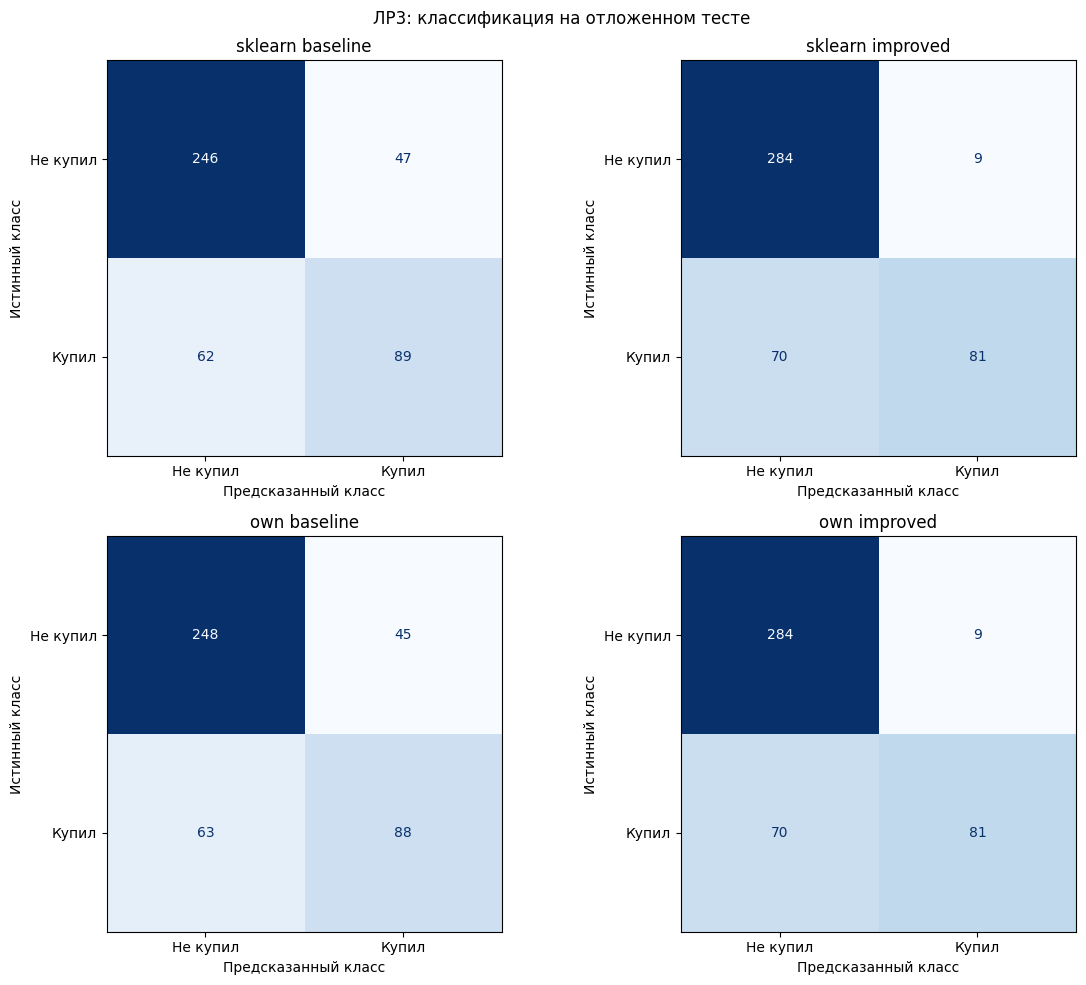

Правильные ответы и ошибки классификации:


,model,tn,fp,fn,tp
0,sklearn baseline,246,47,62,89
1,sklearn improved,284,9,70,81
2,own baseline,248,45,63,88
3,own improved,284,9,70,81


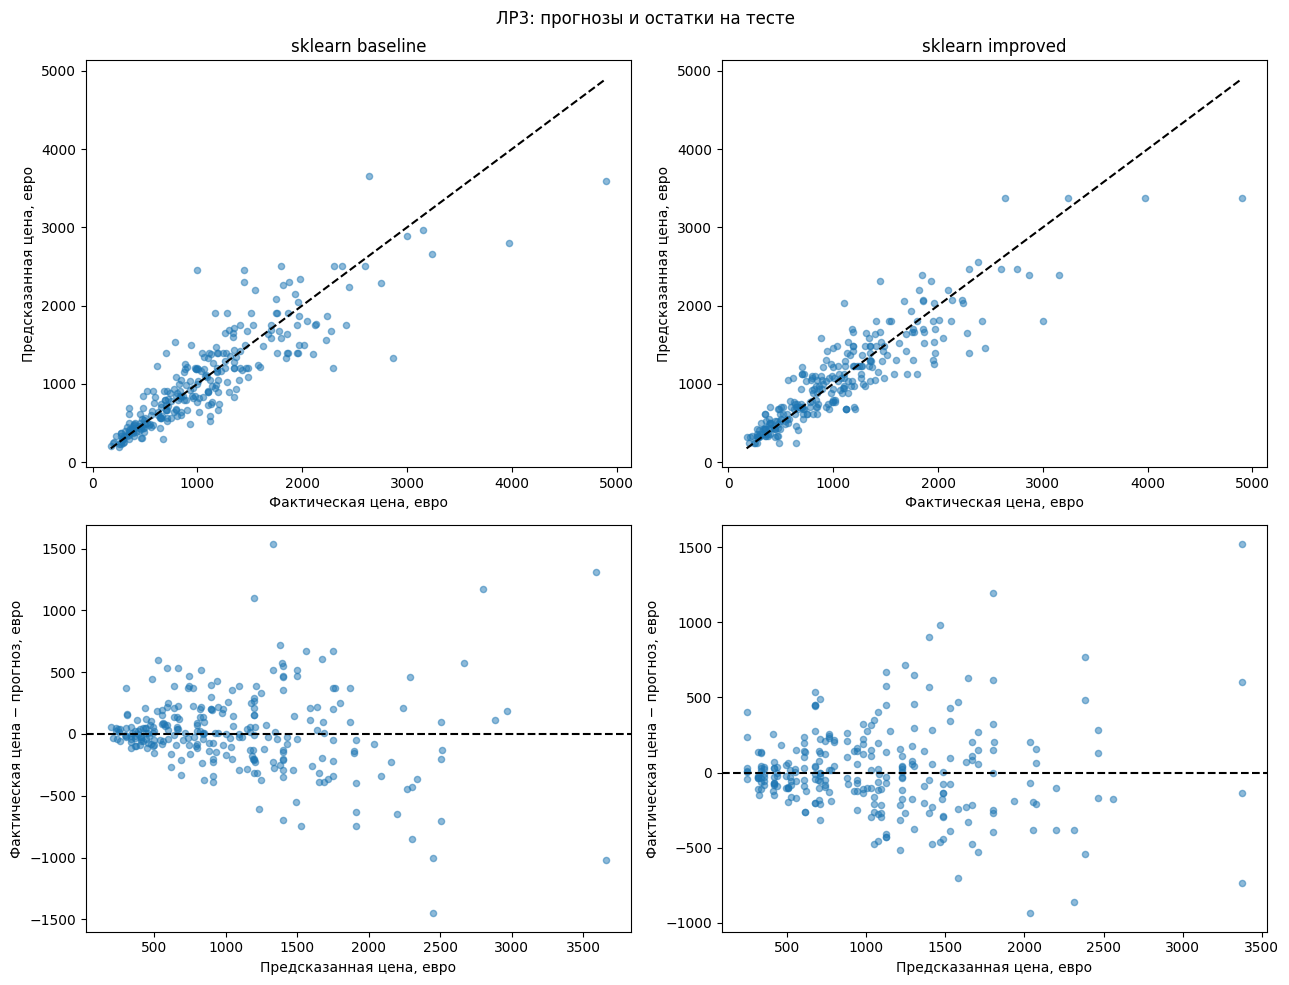

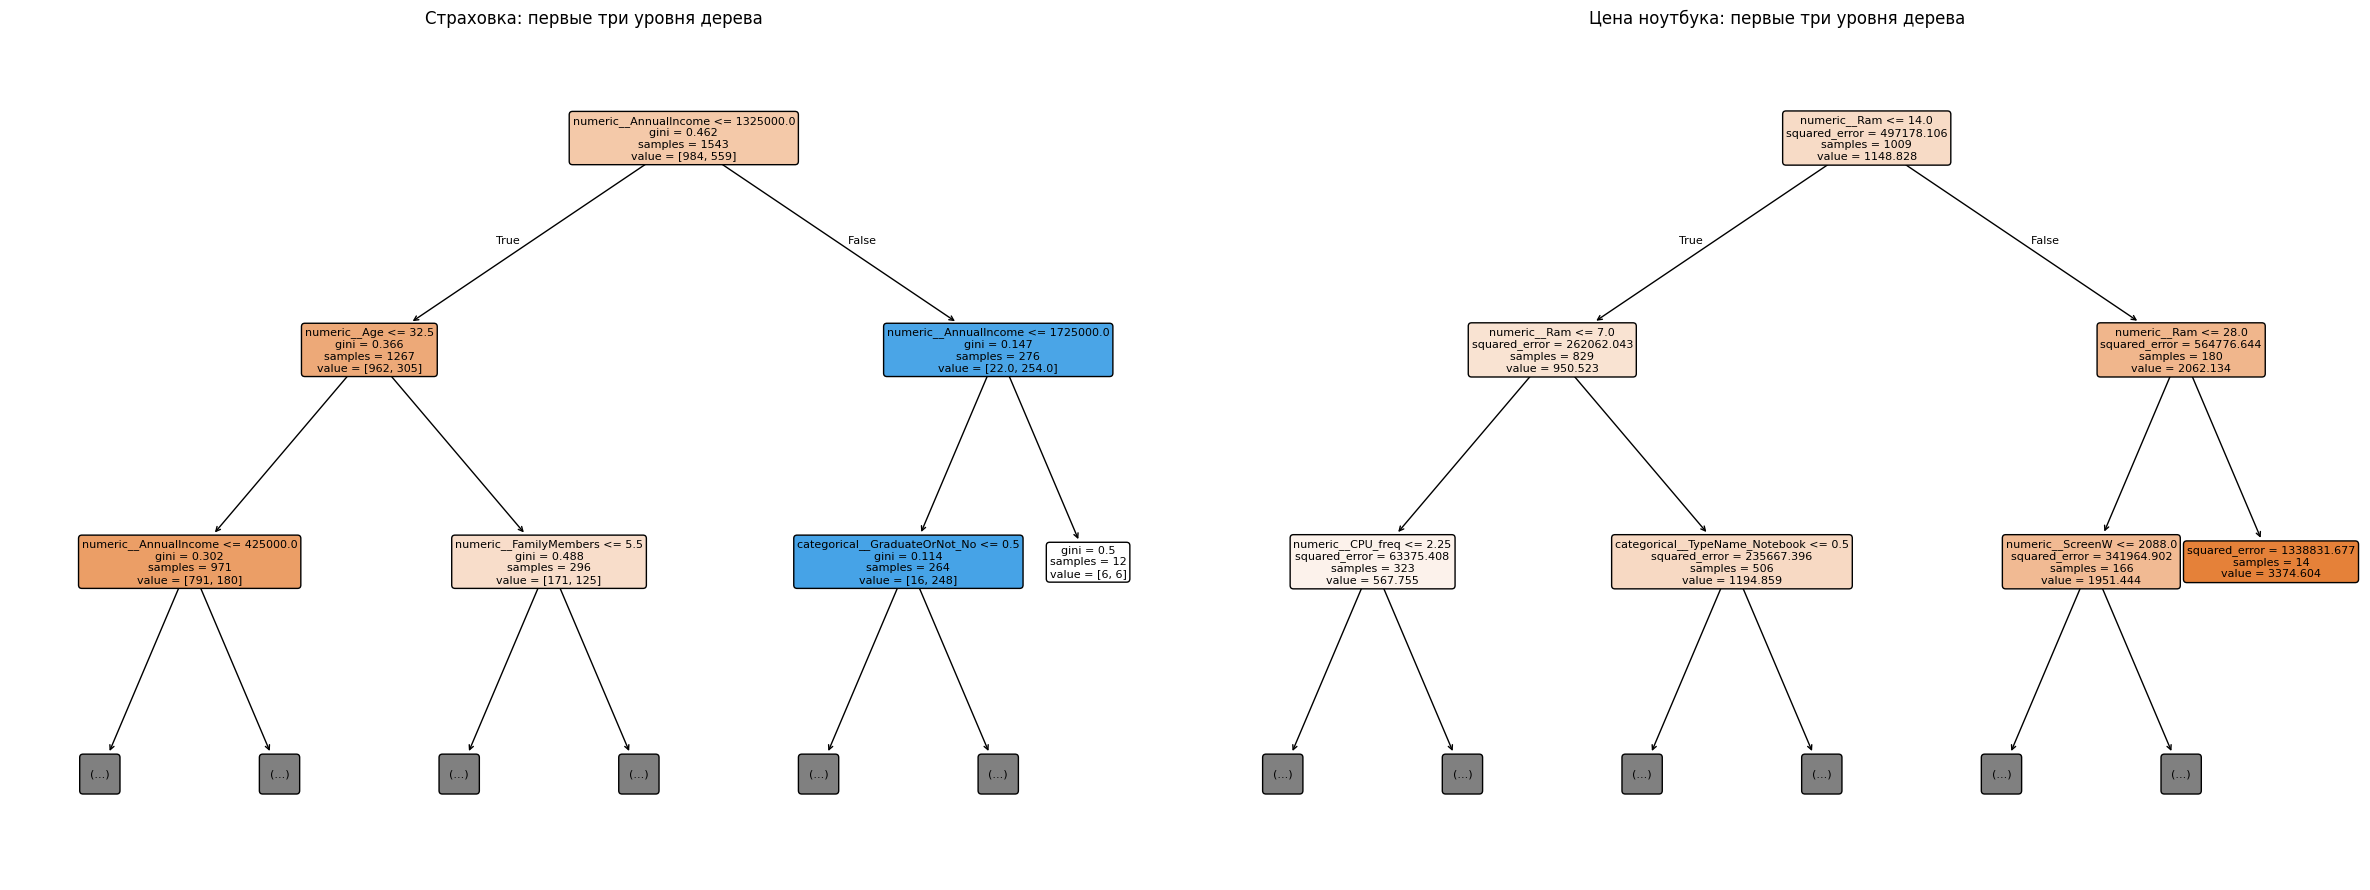

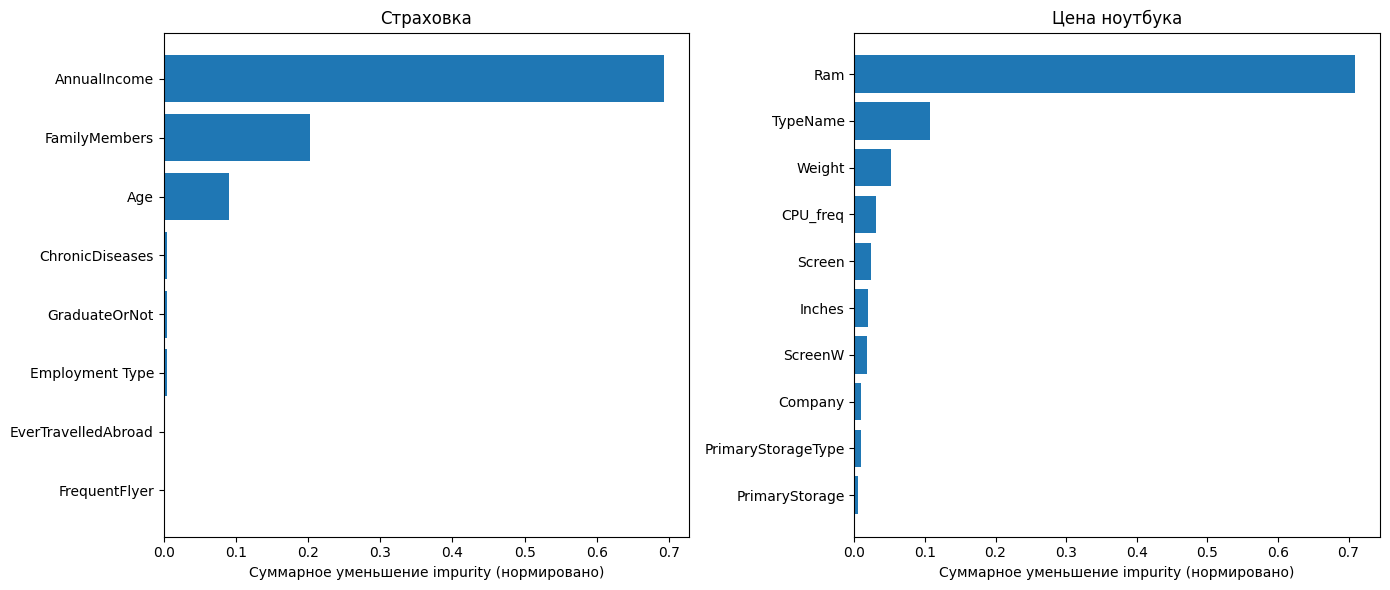

Распределение абсолютных ошибок регрессии, евро:


,model,median_abs_error,p90_abs_error,max_abs_error
0,sklearn baseline,148.24,517.50,1539.99
1,sklearn improved,143.74,465.63,1524.40
2,own baseline,146.00,562.00,1539.99
3,own improved,143.74,465.63,1524.40


Восемь наибольших ошибок выбранного библиотечного регрессора:


,row_position,target,prediction,residual,absolute_error
119,610,4899.00,3374.60,1524.40,1524.40
48,247,2999.00,1800.90,1198.10,1198.10
8,58,2449.00,1463.24,985.76,985.76
155,767,1099.00,2036.20,-937.20,937.20
242,1146,2296.95,1396.09,900.86,900.86
16,88,1449.00,2314.33,-865.33,865.33
193,955,3154.00,2385.55,768.45,768.45
66,329,2639.00,3374.60,-735.60,735.60


Характеристики трёх объектов с наибольшими ошибками:


,row_position,Company,Product,TypeName,Ram,Price_euros
610,610,Lenovo,Thinkpad P51,Notebook,32,4899.0
247,247,Asus,Rog G701VIK-BA060T,Gaming,16,2999.0
58,58,MSI,GS73VR 7RG,Gaming,16,2449.0


Архив результатов подготовлен: lab3_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
"""Разбираем ошибки деревьев, строим графики и сохраняем результаты ЛР3."""

import importlib.metadata
import zipfile
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.tree import plot_tree

figure_dir = results_dir / "lab3_figures"
figure_dir.mkdir(parents=True, exist_ok=True)

# Строки матрицы — истинный класс, столбцы — предсказанный.
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
confusion_rows = []
for ax, name in zip(axes.flat, final_models_cls):
    predicted = final_predictions_cls[name].to_numpy()
    matrix = confusion_matrix(y_test_cls, predicted, labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=["Не купил", "Купил"]).plot(
        ax=ax, cmap="Blues", colorbar=False,
    )
    ax.set_title(name)
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Истинный класс")
    tn, fp, fn, tp = matrix.ravel()
    confusion_rows.append({"model": name, "tn": tn, "fp": fp, "fn": fn, "tp": tp})
fig.suptitle("ЛР3: классификация на отложенном тесте")
fig.tight_layout()
fig.savefig(figure_dir / "lab3_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()
confusion_table = pd.DataFrame(confusion_rows)
confusion_table.to_csv(results_dir / "lab3_confusion_counts.csv", index=False)
print("Правильные ответы и ошибки классификации:")
display(confusion_table)

# Показываем исходную модель и вариант, выбранный по CV.
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
target = final_predictions_reg["target"].to_numpy()
for column, name in enumerate(["sklearn baseline", "sklearn improved"]):
    predicted = final_predictions_reg[name].to_numpy()
    low, high = min(target.min(), predicted.min()), max(target.max(), predicted.max())
    axes[0, column].scatter(target, predicted, alpha=0.5, s=20)
    axes[0, column].plot([low, high], [low, high], "k--")
    axes[0, column].set(title=name, xlabel="Фактическая цена, евро",
                        ylabel="Предсказанная цена, евро")
    axes[1, column].scatter(predicted, target - predicted, alpha=0.5, s=20)
    axes[1, column].axhline(0, color="black", linestyle="--")
    axes[1, column].set(xlabel="Предсказанная цена, евро",
                        ylabel="Фактическая цена − прогноз, евро")
fig.suptitle("ЛР3: прогнозы и остатки на тесте")
fig.tight_layout()
fig.savefig(figure_dir / "lab3_regression_errors.png", dpi=150, bbox_inches="tight")
plt.show()

# Структура обучена только на train. Для читаемости показаны первые уровни.
fig, axes = plt.subplots(1, 2, figsize=(24, 9))
for ax, task, pipeline in [
    (axes[0], "Страховка", final_models_cls["sklearn improved"]),
    (axes[1], "Цена ноутбука", final_models_reg["sklearn improved"]),
]:
    feature_names = pipeline.named_steps["preprocessor"].get_feature_names_out()
    plot_tree(pipeline.named_steps["model"], feature_names=feature_names,
              max_depth=2, filled=True, rounded=True, fontsize=8, ax=ax)
    ax.set_title(f"{task}: первые три уровня дерева")
fig.tight_layout()
fig.savefig(figure_dir / "lab3_tree_structure.png", dpi=150, bbox_inches="tight")
plt.show()

# Складываем важности one-hot столбцов каждой исходной категории.
# Это уменьшение impurity на train, а не причинный эффект признака.
importance_rows = []
for task, models in [("classification", final_models_cls), ("regression", final_models_reg)]:
    for name, pipeline in models.items():
        preprocessor = pipeline.named_steps["preprocessor"]
        original_columns = []
        for transformer_name, transformer, columns in preprocessor.transformers_:
            if transformer_name == "numeric":
                original_columns.extend(columns)
            elif transformer_name == "categorical":
                for column, categories in zip(columns, transformer.categories_):
                    original_columns.extend([column] * len(categories))
        values = pipeline.named_steps["model"].feature_importances_
        assert len(values) == len(original_columns)
        grouped = pd.Series(values, index=original_columns).groupby(level=0).sum()
        for feature, value in grouped.items():
            importance_rows.append({"task": task, "model": name,
                                    "feature": feature, "importance": value})
importance_table = pd.DataFrame(importance_rows)
importance_table.to_csv(results_dir / "lab3_feature_importances.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, task, title in zip(axes, ["classification", "regression"], ["Страховка", "Цена ноутбука"]):
    selected = importance_table[
        (importance_table["task"] == task)
        & (importance_table["model"] == "sklearn improved")
    ].nlargest(10, "importance").sort_values("importance")
    ax.barh(selected["feature"], selected["importance"])
    ax.set(title=title, xlabel="Суммарное уменьшение impurity (нормировано)")
fig.tight_layout()
fig.savefig(figure_dir / "lab3_feature_importances.png", dpi=150, bbox_inches="tight")
plt.show()

error_rows = []
for name in final_models_reg:
    predicted = final_predictions_reg[name].to_numpy()
    absolute = np.abs(target - predicted)
    error_rows.append({
        "model": name,
        "median_abs_error": np.median(absolute),
        "p90_abs_error": np.quantile(absolute, 0.9),
        "max_abs_error": absolute.max(),
    })
error_summary = pd.DataFrame(error_rows)
error_summary.to_csv(results_dir / "lab3_regression_error_summary.csv", index=False)
errors = final_predictions_reg[["row_position", "target"]].copy()
errors["prediction"] = final_predictions_reg["sklearn improved"]
errors["residual"] = errors["target"] - errors["prediction"]
errors["absolute_error"] = errors["residual"].abs()
errors = errors.sort_values("absolute_error", ascending=False)
errors.to_csv(results_dir / "lab3_regression_error_details.csv", index=False)
print("Распределение абсолютных ошибок регрессии, евро:")
display(error_summary.round(2))
print("Восемь наибольших ошибок выбранного библиотечного регрессора:")
display(errors.head(8).round(2))
worst_rows = errors.head(3)["row_position"].to_numpy()
worst_objects = laptops.loc[
    worst_rows, ["Company", "Product", "TypeName", "Ram", "Price_euros"],
].copy()
worst_objects.insert(0, "row_position", worst_objects.index)
print("Характеристики трёх объектов с наибольшими ошибками:")
display(worst_objects)
worst_objects.to_csv(results_dir / "lab3_worst_laptops.csv", index=False)

# Сохраняем фактические индексы и части CV, чтобы проверить повторный запуск.
for name, X, group_ids, train_indices, test_indices, folds in [
    ("travel", X_cls, groups_cls, train_idx_cls, test_idx_cls, cv_folds_cls),
    ("laptops", X_reg, groups_reg, train_idx_reg, test_idx_reg, cv_folds_reg),
]:
    split_table = pd.DataFrame({"row_position": np.arange(len(X)), "group": group_ids})
    split_table["split"] = "train"
    split_table.loc[test_indices, "split"] = "test"
    split_table["validation_fold"] = -1
    for fold, (_, validation_positions) in enumerate(folds):
        split_table.loc[train_indices[validation_positions], "validation_fold"] = fold
    split_table.to_csv(results_dir / f"lab3_split_{name}.csv", index=False)

settings = {
    "random_state": RANDOM_STATE,
    "source_sha256": source_hashes,
    "split_fingerprints": expected_protocol,
    "selected_classification": SELECTED_TREE_CLS,
    "selected_regression": SELECTED_TREE_REG,
    "primary_metrics": {"classification": "macro_f1", "regression": "mae"},
    "versions": {"python": sys.version.split()[0], **{
        name: importlib.metadata.version(name)
        for name in ["numpy", "pandas", "scikit-learn", "matplotlib", "seaborn"]
    }},
    "timing_note": "Один запуск, с предобработкой; predict_proba измерено отдельно.",
}
(results_dir / "lab3_settings.json").write_text(
    json.dumps(settings, ensure_ascii=False, indent=2), encoding="utf-8",
)
archive_path = Path("/content/lab3_artifacts.zip")
with zipfile.ZipFile(archive_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(results_dir.rglob("lab3_*")):
        if path.is_file():
            archive.write(path, arcname=str(path.relative_to(results_dir)))
print("Архив результатов подготовлен:", archive_path.name)
files.download(str(archive_path))

### Что показывают ошибки

У библиотечного классификатора число ложных срабатываний уменьшилось
с 47 до 9, а число пропущенных покупателей выросло с 62 до 70.
Это объясняет одновременный рост precision и снижение recall.
Настроенный собственный классификатор получил ту же матрицу ошибок:
284 верных ответа для непокупателей, 9 ложных срабатываний,
70 пропущенных и 81 найденный покупатель.

У библиотечного регрессора медианная абсолютная ошибка уменьшилась
с 148.24 до 143.74 евро, а 90-й процентиль — с 517.50 до 465.63 евро.
Значит, улучшилась не только средняя ошибка. При этом максимальный
промах остался большим — 1524.40 евро.

Крупнейшие ошибки выбранного регрессора относятся к Lenovo Thinkpad P51,
Asus Rog G701VIK-BA060T и MSI GS73VR 7RG. Их характеристики и прогнозы
приведены выше. По этим трём объектам нельзя установить общую причину
всех ошибок. Дерево выдаёт среднюю цену объектов обучающего листа,
поэтому отдельная дорогая конфигурация может оцениваться недостаточно
точно даже при хорошем среднем качестве.

## Итоговые выводы

Ограничение сложности помогло обеим задачам. Для страховки я выбрал
глубину 5 и минимум 10 объектов в листе. На тесте macro-F1 модели sklearn
вырос с 0.7194 до 0.7750. При этом precision вырос, а recall снизился:
модель реже делает ложные положительные прогнозы, но пропускает
больше покупателей.

Для цены ноутбука выбрано минимум 10 объектов в листе без ограничения
глубины. MAE sklearn снизилась с 222.19 до 208.76 евро.
На полном train число листьев уменьшилось с 938 до 76.

Реализации на NumPy дали близкое качество: после настройки
macro-F1 = 0.7750, MAE = 208.34 евро. Проверки порогов, вероятностей
и ограничений роста прошли. Небольшие различия прогнозов возможны
при выборе разных разделений с одинаковым улучшением.

Параметры выбирались по групповой CV. После оценки на тесте я их
не менял. Крупные ошибки отдельных ноутбуков остаются, поэтому
одной средней MAE недостаточно для оценки каждого прогноза.